# Dự báo khách ngày với lịch sử khả dụng và inner validation

So sánh Holt–Winters, residual HistGB-L1, residual ExtraTrees-L1 và B4 matched, delay nhãn một ngày.

Bản viết lại từ `history_demand_causal_methods.ipynb`, bản cũ được giữ nguyên.
Chọn kernel `.venv`, chạy từ trên xuống (Restart Kernel → Run All).
Nguồn mặc định là snapshot cố định đã lưu, không cần PostgreSQL hoặc `docs/ml` cũ.
Quality PASS là evidence của snapshot, không phải kiểm tra DB mới.
Target là khách của booking cuối cùng không hủy theo ngày đến, không phải occupancy/check-in thực.
Holdout 06–08/2017 đã được xem ở thí nghiệm trước, kết quả là hồi cứu, mang tính khám phá.

## 1. Thiết lập

Chỉ dùng các thư viện đã có trong `ml/requirements.txt`. Mỗi lần chạy tạo
thư mục artifact riêng, không sửa dữ liệu nguồn hoặc kết quả cũ.

In [1]:
import hashlib
import importlib.metadata
import json
import platform
from datetime import datetime, timezone
from pathlib import Path
from uuid import uuid4
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'pipeline/config/dw_operations.json').is_file())
pd.set_option('display.max_columns', None, 'display.max_rows', None, 'display.width', 160)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})

In [2]:
SOURCE_DIR = ROOT / 'artifacts/forecasting/history_demand_causal_methods/20261109T110426_146bf398'
NOTEBOOK_PATH = ROOT / 'notebooks/experiments/history_demand_causal_methods_report.ipynb'
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S') + '_' + uuid4().hex[:8]
OUT = ROOT / 'artifacts/forecasting/history_demand_causal_methods_report' / RUN_ID
OUT.mkdir(parents=True, exist_ok=False)
DAY = pd.Timedelta(days=1)
TRAIN_START, TEST_END = pd.Timestamp('2015-07-01'), pd.Timestamp('2017-08-31')
SEED = 42
print('Artifacts:', OUT.relative_to(ROOT))

Artifacts: artifacts\forecasting\history_demand_causal_methods_report\20261110T051148_90f6fbc3


In [3]:
def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def save_json(name, value):
    with (OUT / name).open('x', encoding='utf-8') as handle:
        json.dump(value, handle, ensure_ascii=False, indent=2, default=str, allow_nan=False)
def save_csv(name, frame):
    frame.to_csv(OUT / name, index=False, float_format='%.12g')
save_json('environment.json', {'python': platform.python_version(), **{
    name: importlib.metadata.version(name) for name in ('numpy', 'pandas', 'matplotlib', 'scikit-learn')}})

## 2. Load data và kiểm tra nguồn

Kiểm tra checksum trước khi đọc. Daily và booking phải thuộc cùng published snapshot,
khóa booking là checksum nguồn + row ordinal. Không gộp dòng vì giống thuộc tính.

In [4]:
inventory = json.loads((SOURCE_DIR / 'input_manifest.json').read_text(encoding='utf-8'))
for name in ('daily_input.csv', 'booking_input.csv', 'provenance.json', 'quality.json'):
    assert sha(SOURCE_DIR / name) == inventory[name], f'Input changed: {name}'
provenance = json.loads((SOURCE_DIR / 'provenance.json').read_text(encoding='utf-8'))
quality = json.loads((SOURCE_DIR / 'quality.json').read_text(encoding='utf-8'))
assert all(q['passed'] and not q['errors'] for q in quality.values())
assert all(q['data_version'] == provenance['data_version'] for q in quality.values())
daily = pd.read_csv(SOURCE_DIR / 'daily_input.csv', parse_dates=['full_date'])
bookings = pd.read_csv(SOURCE_DIR / 'booking_input.csv', parse_dates=['full_date'])
print('Data version:', provenance['data_version'])
pd.DataFrame({'dataset': ['daily', 'booking'], 'rows': [len(daily), len(bookings)]})

Data version: 323b1759-994c-4c66-8ca3-8d73e5a11acb


,dataset,rows
0,daily,793
1,booking,79250


In [5]:
daily_ints = ['date_key', 'observed_total_guests', 'target_guests', 'non_canceled_bookings',
              'guest_valid_booking_count', 'missing_guest_bookings_count',
              'guest_ineligible_booking_count', 'rejected_booking_count', 'excluded_booking_count']
for frame, names in ((daily, daily_ints), (bookings, ['source_row_id', 'is_canceled', 'total_guests'])):
    for name in names:
        values = pd.to_numeric(frame[name], errors='raise')
        frame[name] = values.astype('Int64')
assert pd.DatetimeIndex(daily.full_date).equals(pd.date_range(TRAIN_START, TEST_END))
assert set(daily.data_version) == {provenance['data_version']}
assert daily.guest_data_status.eq('COMPLETE').equals(daily.target_guests.notna())
assert set(bookings.source_file_sha256) == {provenance['source_checksums']['booking']}

In [6]:
valid = bookings[(bookings.is_canceled == 0) & bookings.guest_eligible].copy()
observed = valid.groupby('full_date').total_guests.agg(['sum', 'count'])
observed = observed.reindex(daily.full_date, fill_value=0)
np.testing.assert_array_equal(observed['sum'], daily.observed_total_guests)
np.testing.assert_array_equal(observed['count'], daily.guest_valid_booking_count)
source_hashes = {name: sha(SOURCE_DIR / name) for name in inventory}
old_paths = [p for p in (ROOT / 'notebooks').rglob('*.ipynb') if not p.stem.endswith('_report')]
old_hashes = {str(p.relative_to(ROOT)): sha(p) for p in old_paths}
save_json('source.json', {'snapshot': str(SOURCE_DIR.relative_to(ROOT)), 'provenance': provenance,
                          'input_checksums': source_hashes, 'point_in_time_verified': False})

### Bổ sung loại phòng đặt

Snapshot booking chưa có loại phòng. Đọc `reserved_room_type` từ đúng raw đã ghim
checksum, ghép bằng row ordinal, chỉ giữ booking đã có trong snapshot.
Đây là thuộc tính phục vụ bù nhãn, không phải feature tương lai đưa vào model.

In [7]:
source_set = json.loads((ROOT / 'docs/data_dictionary/operations_source_set.json').read_text(encoding='utf-8'))
room_source = source_set['sources']['booking']
room_path = ROOT / room_source['file']
assert sha(room_path) == room_source['sha256'] == provenance['source_checksums']['booking']
room_rows = pd.read_csv(room_path, usecols=['reserved_room_type'], keep_default_na=False)
room_rows['source_row_id'] = np.arange(2, len(room_rows) + 2)
bookings = bookings.merge(room_rows, on='source_row_id', how='left', validate='one_to_one', indicator=True)
assert bookings._merge.eq('both').all(), 'Room source does not cover the snapshot'
bookings = bookings.drop(columns='_merge')
bookings['reserved_room_type'] = bookings.reserved_room_type.astype('string').str.strip().replace('', pd.NA)
valid = bookings[bookings.is_canceled.eq(0) & bookings.guest_eligible].copy()
save_json('room_source.json', {'file': room_source['file'], 'sha256': sha(room_path),
                             'join_key': 'source checksum + source_row_id', 'rows': len(bookings)})
bookings[['source_row_id', 'full_date', 'reserved_room_type', 'total_guests', 'guest_eligible']].head()

,source_row_id,full_date,reserved_room_type,total_guests,guest_eligible
0,40062,2015-07-01,A,1,True
1,40063,2015-07-01,A,2,True
2,40064,2015-07-01,A,1,True
3,40065,2015-07-01,A,2,True
4,74968,2015-07-01,A,2,True


## 3. Chia dữ liệu và fold

Dùng `sklearn.model_selection.TimeSeriesSplit(n_splits=3)` trên trục ngày
development 07/2015–05/2017. Ba validation fold có cùng số ngày, train mở rộng dần.
Giữ đủ ngày khi chia, không drop ngày thiếu hoặc fit imputer trên toàn bộ dữ liệu.
Mean bù, median và scaler vẫn chỉ học từ train của từng fold.
Holdout 06–08/2017 tách riêng. Dự báo cuối ngày t cho t+1…t+7, origin từ
eval_start−1 đến eval_end−7 để mọi origin có đủ 7 horizon.
Delay nhãn = **1 ngày** là giả định khả dụng, cutoff nhãn lùi trong train tương ứng.
Chọn model bằng trung bình đều MAE ba fold, trong 1% ưu tiên model đơn giản.

In [8]:
from sklearn.model_selection import TimeSeriesSplit
HORIZONS = tuple(range(1, 8))
DELAY = 1
DEV_END = pd.Timestamp('2017-05-31')
development_dates = pd.DatetimeIndex(daily.loc[daily.full_date.le(DEV_END), 'full_date'])
splitter = TimeSeriesSplit(n_splits=3)
FOLDS = []
for number, (train_index, val_index) in enumerate(splitter.split(development_dates), 1):
    FOLDS.append({'fold': f'F{number}',
        'train_end': str(development_dates[train_index[-1]].date()),
        'eval_start': str(development_dates[val_index[0]].date()),
        'eval_end': str(development_dates[val_index[-1]].date())})

In [9]:
HOLDOUT = {'fold': 'Holdout', 'train_end': '2017-05-31', 'eval_start': '2017-06-01', 'eval_end': '2017-08-31'}
fold_table = pd.DataFrame(FOLDS + [HOLDOUT])
fold_table['train_days'] = (pd.to_datetime(fold_table.train_end) - TRAIN_START).dt.days + 1
fold_table['eval_days'] = (pd.to_datetime(fold_table.eval_end) - pd.to_datetime(fold_table.eval_start)).dt.days + 1
fold_table['available_train_end'] = pd.to_datetime(fold_table.train_end) - DELAY * DAY
save_csv('fold_manifest.csv', fold_table)
fold_table

,fold,train_end,eval_start,eval_end,train_days,eval_days,available_train_end
0,F1,2015-12-23,2015-12-24,2016-06-15,176,175,2015-12-22
1,F2,2016-06-15,2016-06-16,2016-12-07,351,175,2016-06-14
2,F3,2016-12-07,2016-12-08,2017-05-31,526,175,2016-12-06
3,Holdout,2017-05-31,2017-06-01,2017-08-31,701,92,2017-05-30


In [10]:
def schedule(start, end):
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    origins = pd.date_range(start - DAY, end - 7 * DAY)
    return pd.DataFrame([(t, h, t + h * DAY) for t in origins for h in HORIZONS],
                        columns=['origin', 'horizon', 'target_date'])

## 4. Tiền xử lý nhãn và lịch sử khả dụng

Feature của origin t chỉ dùng history đến t−1. PARTIAL trong history được bù
bằng cumulative mean khách/booking theo loại phòng của các ngày trước ngày đó.
Nhóm ít mẫu dùng cumulative mean chung. Train/evaluation target dùng mean theo phòng
của train khả dụng của fold, COMPLETE và zero giữ nguyên.
Không có OTB, observed weather tương lai hoặc subtotal/count của ngày đích trong feature.
“Causal” ở đây là thứ tự thời gian, không phải suy luận tác động nhân quả.

### Mean theo loại phòng trong train

Tính số khách/booking hợp lệ, không hủy, theo `reserved_room_type`.
Nhóm có ít nhất **30 booking** dùng mean riêng, nhóm ít mẫu/không biết/chưa gặp
dùng mean chung train. Ngưỡng 30 cố định, không chọn bằng điểm test.
Bù từng booking ZERO_GUESTS đủ điều kiện rồi cộng với subtotal quan sát của ngày.
Giữ nguyên ngày COMPLETE và zero hợp lệ. Nhãn sau bù vẫn là ước tính.

In [11]:
MIN_ROOM_BOOKINGS = 30
IMPUTATION_POLICY = {'method': 'room_type_mean', 'group_column': 'reserved_room_type',
                     'min_room_bookings': MIN_ROOM_BOOKINGS, 'fallback': 'train_global_mean'}
def fit_room_imputer(cutoff):
    train = valid[valid.full_date.between(TRAIN_START, pd.Timestamp(cutoff))]
    mu = float(train.total_guests.mean())
    rooms = train.groupby('reserved_room_type').total_guests.agg(['count', 'sum', 'mean'])
    rooms['use_room_mean'] = rooms['count'].ge(MIN_ROOM_BOOKINGS)
    rooms['fill_mean'] = rooms['mean'].where(rooms.use_room_mean, mu)
    return {**IMPUTATION_POLICY, 'mu_train': mu, 'fit_start': str(TRAIN_START.date()),
            'fit_end': str(pd.Timestamp(cutoff).date()), 'fit_label_cutoff': str(pd.Timestamp(cutoff).date()),
            'known_guest_sum': int(train.total_guests.sum()), 'known_booking_count': len(train),
            'rooms': rooms.to_dict(orient='index')}

In [12]:
def room_mean_table(imputer):
    return pd.DataFrame.from_dict(imputer['rooms'], orient='index').rename_axis('reserved_room_type').reset_index()
def room_estimates(imputer, end):
    mask = bookings.is_canceled.eq(0) & ~bookings.guest_eligible & bookings.full_date.le(pd.Timestamp(end))
    missing = bookings.loc[mask].copy()
    means = {room: stats['fill_mean'] for room, stats in imputer['rooms'].items()}
    used = {room: stats['use_room_mean'] for room, stats in imputer['rooms'].items()}
    missing['estimated_guests'] = missing.reserved_room_type.map(means).astype(float).fillna(imputer['mu_train'])
    missing['imputation_source'] = np.where(missing.reserved_room_type.map(used).eq(True), 'ROOM_MEAN', 'GLOBAL_MEAN')
    return missing
def save_room_imputation(prefix, imputer, end):
    save_json(prefix + '_imputer.json', imputer)
    save_csv(prefix + '_room_means.csv', room_mean_table(imputer))
    save_csv(prefix + '_imputed_bookings.csv', room_estimates(imputer, end))

In [13]:
def eligible_imputation(frame):
    return (frame.guest_data_status.eq('PARTIAL') & frame.booking_data_status.eq('COMPLETE')
            & frame.rejected_booking_count.eq(frame.excluded_booking_count)
            & frame.missing_guest_bookings_count.gt(0)
            & frame.guest_ineligible_booking_count.eq(frame.missing_guest_bookings_count)
            & frame.non_canceled_bookings.eq(frame.guest_valid_booking_count + frame.missing_guest_bookings_count))

In [14]:
def room_labels(cutoff, end):
    frame = daily[daily.full_date.le(pd.Timestamp(end))].copy()
    imputer = fit_room_imputer(cutoff)
    additions = room_estimates(imputer, end).groupby('full_date').estimated_guests.sum()
    frame['target_true'] = frame.target_guests.astype(float)
    frame['estimated_missing_guests'] = frame.full_date.map(additions).fillna(0.)
    mask = eligible_imputation(frame)
    frame.loc[~mask, 'estimated_missing_guests'] = 0.
    frame['target_estimated'] = frame.target_true.copy()
    frame.loc[mask, 'target_estimated'] = (frame.loc[mask, 'observed_total_guests'].astype(float)
                                         + frame.loc[mask, 'estimated_missing_guests'])
    frame['target_is_imputed'] = mask.to_numpy(dtype=bool)
    frame['partition'] = np.where(frame.full_date.le(pd.Timestamp(cutoff)), 'train', 'evaluation')
    return frame, imputer

In [15]:
preview_imputer = fit_room_imputer(pd.Timestamp(FOLDS[0]['train_end']) - DELAY * DAY)
print('Mean chung train:', round(preview_imputer['mu_train'], 6), ', tối thiểu', MIN_ROOM_BOOKINGS, 'booking/loại phòng')
room_mean_table(preview_imputer).round(4)

Mean chung train: 1.779509 , tối thiểu 30 booking/loại phòng


,reserved_room_type,count,sum,mean,use_room_mean,fill_mean
0,A,6361,10903,1.7140,True,1.7140
1,B,139,292,2.1007,True,2.1007
2,C,2,5,2.5000,False,1.7795
3,D,562,1108,1.9715,True,1.9715
4,E,42,75,1.7857,True,1.7857
5,F,129,476,3.6899,True,3.6899
6,G,17,46,2.7059,False,1.7795


In [16]:
def causal_room_estimates(frame, booking_frame=None):
    source = bookings if booking_frame is None else booking_frame
    known = source[source.is_canceled.eq(0) & source.guest_eligible]
    mask = source.is_canceled.eq(0) & ~source.guest_eligible & source.full_date.isin(frame.full_date)
    missing = source.loc[mask].copy()
    counts = frame.guest_valid_booking_count.astype(float).cumsum().shift(1)
    mu = frame.observed_total_guests.astype(float).cumsum().shift(1) / counts.where(counts.gt(0))
    mu.index = pd.DatetimeIndex(frame.full_date)
    missing['past_global_mean'] = missing.full_date.map(mu)
    missing['estimated_guests'] = missing.past_global_mean
    missing['room_known_count'] = 0
    missing['imputation_source'] = 'GLOBAL_MEAN'
    for room, group in missing.groupby('reserved_room_type', dropna=False):
        room_known = known[known.reserved_room_type.eq(room).fillna(False)]
        prior = room_known.groupby('full_date').total_guests.agg(['sum', 'count'])
        prior = prior.reindex(pd.DatetimeIndex(frame.full_date), fill_value=0).cumsum().shift(1, fill_value=0)
        n = prior['count'].reindex(group.full_date).to_numpy()
        mean = (prior['sum'] / prior['count'].where(prior['count'].ge(MIN_ROOM_BOOKINGS))).reindex(group.full_date).to_numpy(dtype=float)
        use_room = np.isfinite(mean)
        missing.loc[group.index, 'estimated_guests'] = np.where(use_room, mean, group.past_global_mean)
        missing.loc[group.index, 'room_known_count'] = n
        missing.loc[group.index, 'imputation_source'] = np.where(use_room, 'ROOM_MEAN', 'GLOBAL_MEAN')
    return missing

In [17]:
def causal_history(frame, booking_frame=None):
    missing = causal_room_estimates(frame, booking_frame)
    additions = missing.groupby('full_date').estimated_guests.sum(min_count=1)
    added = frame.full_date.map(additions)
    series = frame.target_guests.astype(float).copy()
    mask = eligible_imputation(frame) & added.notna()
    series.loc[mask] = frame.loc[mask, 'observed_total_guests'].astype(float) + added.loc[mask]
    series.index = pd.DatetimeIndex(frame.full_date)
    return series
def benchmark_labels(cutoff, end):
    return room_labels(cutoff, end)

In [18]:
HISTORY = causal_history(daily)
save_csv('causal_history.csv', pd.DataFrame({'full_date': HISTORY.index, 'history_target': HISTORY.to_numpy()}))
save_csv('causal_imputed_bookings.csv', causal_room_estimates(daily))

In [19]:
def past_features(series, asof):
    values = {}
    for lag in (0, 1, 2, 6, 7, 13, 14, 20, 27, 55, 83):
        values[f'past_lag_{lag}'] = series.reindex(asof - lag * DAY).to_numpy()
    for window in (7, 14, 28, 56, 84):
        roll = series.rolling(window, min_periods=3)
        statistics = {'mean': roll.mean(), 'median': roll.median(),
                      'std': roll.std(ddof=0), 'count': roll.count()}
        for name, stat in statistics.items():
            values[f'{name}_{window}'] = stat.reindex(asof).to_numpy()
    return values
def weekday_offset(series, asof, target):
    residual = series - series.shift(1).rolling(14, min_periods=7).mean()
    offset = np.zeros(len(target))
    for weekday in range(7):
        r = residual.where(series.index.day_of_week == weekday)
        n = r.rolling(56, min_periods=1).count().reindex(asof).to_numpy()
        mean = r.rolling(56, min_periods=1).mean().reindex(asof).fillna(0).to_numpy()
        mask = target.day_of_week == weekday
        offset[mask] = (mean * n / (n + 4))[mask]
    return offset

In [20]:
def seasonal_features(series, asof, target):
    values = {}
    for weeks in (4, 8, 12):
        past = []
        for k in range(1, weeks + 1):
            date = target - 7 * k * DAY
            values_at_date = series.reindex(date).to_numpy(copy=True)
            values_at_date[date > asof] = np.nan
            past.append(values_at_date)
        seasonal = pd.DataFrame(np.array(past).T)
        values[f'same_weekday_mean_{weeks}w'] = seasonal.mean(axis=1).to_numpy()
        values[f'same_weekday_median_{weeks}w'] = seasonal.median(axis=1).to_numpy()
    return values

In [21]:
def features(series, pairs):
    asof = pd.DatetimeIndex(pairs.origin - DELAY * DAY)
    target = pd.DatetimeIndex(pairs.target_date)
    values = past_features(series, asof)
    offset = weekday_offset(series, asof, target)
    values['anchor'] = values['mean_14'] + offset
    values['weekday_offset'] = offset
    values.update(seasonal_features(series, asof, target))
    values['recent_level_change'] = values['mean_7'] - values['mean_28']
    values['horizon'] = pairs.horizon.to_numpy()
    for weekday in range(1, 7):
        values[f'target_weekday_{weekday}'] = (target.day_of_week == weekday).astype(float)
    values['target_month_sin'] = np.sin(2 * np.pi * (target.month - 1) / 12)
    values['target_month_cos'] = np.cos(2 * np.pi * (target.month - 1) / 12)
    values['target_year_sin'] = np.sin(2 * np.pi * (target.day_of_year - 1) / 365.25)
    values['target_year_cos'] = np.cos(2 * np.pi * (target.day_of_year - 1) / 365.25)
    values['target_month_start'] = target.is_month_start.astype(float)
    values['target_month_end'] = target.is_month_end.astype(float)
    return pd.DataFrame(values, index=pairs.index, dtype=float)

## 5. Kiến trúc và cấu hình mô hình

A1: Holt–Winters additive mùa tuần, trend giảm dần phi=.9, seed 28 ngày.
A2: HistGB loss absolute_error, 200 iterations, lr=.05, leaf≥28, L2=5, tắt early stopping.
A3: ExtraTrees criterion absolute_error, 100 cây, depth=8, max_features=.8.
Hai model residual học y−anchor, pooled 7 horizon, prediction=anchor+residual, clip≥0.
Anchor=mean14+weekday residual 56 ngày shrink n/(n+4). Trọng số recency half-life 180 ngày.

Feature: lag và rolling 7/14/28/56/84, cùng thứ 4/8/12 tuần, recent level change,
horizon, weekday, sin/cos tháng/năm, đầu/cuối tháng. Median+indicator fit train.
B4_matched dùng MA14 và correction h×weekday dưới cùng delay/history.

In [22]:
from sklearn.ensemble import HistGradientBoostingRegressor, ExtraTreesRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from threadpoolctl import threadpool_limits
METHODS = ('A1_holt_winters', 'A2_residual_histgb', 'A3_residual_extra_trees')
ORDER = ('B4_matched',) + METHODS
INNER_DAYS, RECENCY_HALF_LIFE = 56, 180
GRIDS = {
    'A1_holt_winters': [dict(alpha=a, beta=b, gamma=g, phi=.9)
                       for a in (.2, .5) for b in (0., .05) for g in (.1, .3)],
    'A2_residual_histgb': [dict(max_leaf_nodes=n) for n in (7, 15)],
    'A3_residual_extra_trees': [dict(min_samples_leaf=n) for n in (14, 28)],
}
pd.Series(GRIDS, name='inner search')

A1_holt_winters            [{'alpha': 0.2, 'beta': 0.0, 'gamma': 0.1, 'ph...
A2_residual_histgb           [{'max_leaf_nodes': 7}, {'max_leaf_nodes': 15}]
A3_residual_extra_trees    [{'min_samples_leaf': 14}, {'min_samples_leaf'...
Name: inner search, dtype: object

In [23]:
def holt_prediction(series, pairs, config):
    series = series.loc[:pairs.origin.max() - DELAY * DAY]
    seed = series.iloc[:28].dropna()
    level, trend = float(seed.mean()), 0.
    season = np.array([float(seed[seed.index.day_of_week == w].mean() - level) for w in range(7)])
    alpha, beta, gamma, phi = (config[k] for k in ('alpha', 'beta', 'gamma', 'phi'))
    states = {series.index[27]: (level, trend, season.copy())}
    for date, actual in series.iloc[28:].items():
        w, previous = date.day_of_week, level
        if pd.notna(actual):
            level = alpha * (actual - season[w]) + (1 - alpha) * (level + phi * trend)
            trend = beta * (level - previous) + (1 - beta) * phi * trend
            season[w] = gamma * (actual - level) + (1 - gamma) * season[w]
        else:
            level, trend = level + phi * trend, phi * trend
        states[date] = (level, trend, season.copy())
    result = []
    for row in pairs.itertuples(index=False):
        level, trend, seasonal = states[row.origin - DELAY * DAY]
        steps = row.horizon + DELAY
        damped = phi * (1 - phi ** steps) / (1 - phi)
        result.append(max(0., level + damped * trend + seasonal[row.target_date.day_of_week]))
    return np.array(result)

In [24]:
def make_model(name, config):
    if name == 'A2_residual_histgb':
        estimator = HistGradientBoostingRegressor(loss='absolute_error', max_iter=200,
            learning_rate=.05, min_samples_leaf=28, l2_regularization=5., early_stopping=False,
            random_state=42, **config)
    else:
        estimator = ExtraTreesRegressor(n_estimators=100, criterion='absolute_error', max_depth=8,
            max_features=.8, random_state=42, n_jobs=1, **config)
    return make_pipeline(SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True), estimator)

## 6. Train và chọn hyperparameter bên trong train

Inner validation là 56 ngày cuối train khả dụng. Inner train dừng trước origin
đầu tiên đủ một ngày publication delay. Chọn cấu hình bằng inner MAE, rồi refit
trên outer train khả dụng. Không đọc outer validation/test để chọn hyperparameter.

In [25]:
def training_data(cutoff):
    labels, imputer = benchmark_labels(cutoff, cutoff)
    pairs = schedule(TRAIN_START + 29 * DAY, pd.Timestamp(cutoff))
    x = features(HISTORY, pairs)
    y = labels.set_index('full_date').target_estimated.reindex(pd.DatetimeIndex(pairs.target_date)).to_numpy()
    mask = np.isfinite(y) & np.isfinite(x.anchor.to_numpy())
    return pairs.loc[mask].reset_index(drop=True), x.loc[mask].reset_index(drop=True), y[mask], imputer

### In feature đầu vào

In đủ feature của pooled model và mẫu train F1, gồm origin/horizon/as-of để đối chiếu.
Feature gốc được in trước imputation, cột sau median + missing indicator được in riêng.
A1 dùng history để cập nhật state Holt–Winters, B4_matched dùng mean14 và correction,
không dùng toàn bộ ma trận X của A2/A3. Không đưa target vào feature.

In [26]:
preview_cutoff = pd.Timestamp(FOLDS[0]['train_end']) - DELAY * DAY
preview_pairs, preview_x, preview_y, _ = training_data(preview_cutoff)
feature_catalog = pd.DataFrame({'feature': preview_x.columns,
                                'dtype': preview_x.dtypes.astype(str).to_numpy()})
print('Số feature gốc của A2/A3:', len(feature_catalog))
feature_catalog

Số feature gốc của A2/A3: 53


,feature,dtype
0,past_lag_0,float64
1,past_lag_1,float64
2,past_lag_2,float64
3,past_lag_6,float64
4,past_lag_7,float64
5,past_lag_13,float64
6,past_lag_14,float64
7,past_lag_20,float64
8,past_lag_27,float64
9,past_lag_55,float64


In [27]:
save_csv('feature_catalog.csv', feature_catalog)
preview_pairs.head(3).assign(asof=preview_pairs.origin.head(3) - DELAY * DAY)

,origin,horizon,target_date,asof
0,2015-07-29,1,2015-07-30,2015-07-28
1,2015-07-29,2,2015-07-31,2015-07-28
2,2015-07-29,3,2015-08-01,2015-07-28


In [28]:
preview_x.head(3).T.rename_axis('feature')

,0,1,2
feature,,,
past_lag_0,1.700000e+01,1.700000e+01,17.000000
past_lag_1,5.000000e+01,5.000000e+01,50.000000
past_lag_2,4.000000e+00,4.000000e+00,4.000000
past_lag_6,4.700000e+01,4.700000e+01,47.000000
past_lag_7,0.000000e+00,0.000000e+00,0.000000
past_lag_13,5.000000e+01,5.000000e+01,50.000000
past_lag_14,0.000000e+00,0.000000e+00,0.000000
past_lag_20,4.700000e+01,4.700000e+01,47.000000
past_lag_27,1.160000e+02,1.160000e+02,116.000000


In [29]:
preprocessing = make_model('A2_residual_histgb', GRIDS['A2_residual_histgb'][0])[:-1]
values = preprocessing.fit_transform(preview_x)
names = preprocessing.get_feature_names_out()
print('Số feature sau median + missing indicator (F1):', len(names))
pd.DataFrame({'feature_after_preprocessing': names})

Số feature sau median + missing indicator (F1): 55


,feature_after_preprocessing
0,past_lag_0
1,past_lag_1
2,past_lag_2
3,past_lag_6
4,past_lag_7
5,past_lag_13
6,past_lag_14
7,past_lag_20
8,past_lag_27
9,past_lag_55


In [30]:
pd.DataFrame(values[:3], columns=names).T.rename_axis('feature')

,0,1,2
feature,,,
past_lag_0,1.700000e+01,1.700000e+01,17.000000
past_lag_1,5.000000e+01,5.000000e+01,50.000000
past_lag_2,4.000000e+00,4.000000e+00,4.000000
past_lag_6,4.700000e+01,4.700000e+01,47.000000
past_lag_7,0.000000e+00,0.000000e+00,0.000000
past_lag_13,5.000000e+01,5.000000e+01,50.000000
past_lag_14,0.000000e+00,0.000000e+00,0.000000
past_lag_20,4.700000e+01,4.700000e+01,47.000000
past_lag_27,1.160000e+02,1.160000e+02,116.000000


In [31]:
pd.DataFrame({'model': ORDER, 'đầu vào': [
    'mean_14 + horizon + weekday + residual correction train',
    'History target đến origin−1, level/trend/7 weekday seasons',
    'Toàn bộ feature_catalog, học residual y−anchor',
    'Toàn bộ feature_catalog, học residual y−anchor',
]})

,model,đầu vào
0,B4_matched,mean_14 + horizon + weekday + residual correct...
1,A1_holt_winters,"History target đến origin−1, level/trend/7 wee..."
2,A2_residual_histgb,"Toàn bộ feature_catalog, học residual y−anchor"
3,A3_residual_extra_trees,"Toàn bộ feature_catalog, học residual y−anchor"


In [32]:
def fit_ml(name, config, cutoff, data):
    pairs, x, y, _ = data
    weight = np.exp2(-(pd.Timestamp(cutoff) - pairs.target_date).dt.days.to_numpy() / RECENCY_HALF_LIFE)
    model = make_model(name, config)
    with threadpool_limits(limits=1):
        model.fit(x, y - x.anchor.to_numpy(), **{model.steps[-1][0] + '__sample_weight': weight})
    return model
def predict_ml(model, x):
    with threadpool_limits(limits=1):
        return np.maximum(0., x.anchor.to_numpy() + model.predict(x))

In [33]:
def inner_search(cutoff):
    inner_start = cutoff - (INNER_DAYS - 1) * DAY
    inner_cutoff = inner_start - (1 + DELAY) * DAY
    pairs = schedule(inner_start, cutoff)
    labels, _ = benchmark_labels(inner_cutoff, cutoff)
    actual = labels.set_index('full_date').target_estimated.reindex(pd.DatetimeIndex(pairs.target_date)).to_numpy()
    x, train = features(HISTORY, pairs), training_data(inner_cutoff)
    rows, chosen = [], {}
    for name in METHODS:
        best = np.inf
        for config in GRIDS[name]:
            if name == 'A1_holt_winters':
                predicted = holt_prediction(HISTORY, pairs, config)
            else:
                predicted = predict_ml(fit_ml(name, config, inner_cutoff, train), x)
            mask = np.isfinite(actual)
            mae = float(np.abs(predicted[mask] - actual[mask]).mean())
            rows.append({'model': name, 'config': json.dumps(config), 'inner_MAE': mae,
                         'train_cutoff': inner_cutoff, 'eval_start': inner_start, 'eval_end': cutoff})
            if mae < best:
                best, chosen[name] = mae, config
    return chosen, pd.DataFrame(rows)

In [34]:
def train_bundle(fold):
    first_origin = pd.Timestamp(fold['eval_start']) - DAY
    cutoff = first_origin - DELAY * DAY
    selected, search = inner_search(cutoff)
    data = training_data(cutoff)
    pairs, x, y, imputer = data
    models = {name: fit_ml(name, selected[name], cutoff, data) for name in METHODS[1:]}
    residual = y - x.mean_14.to_numpy()
    correction = np.zeros((7, 7))
    for h in HORIZONS:
        for weekday in range(7):
            mask = pairs.horizon.eq(h) & pairs.target_date.dt.day_of_week.eq(weekday)
            correction[h - 1, weekday] = residual[mask].sum() / (int(mask.sum()) + 10)
    assert pairs.target_date.add(DELAY * DAY).le(first_origin).all()
    labels, _ = benchmark_labels(cutoff, fold['eval_end'])
    save_csv(fold['fold'] + '_inner_search.csv', search)
    save_csv(fold['fold'] + '_training.csv', pd.concat([pairs, x, pd.Series(y, name='training_target')], axis=1))
    save_json(fold['fold'] + '_configuration.json', {'selected': selected, 'imputer': imputer})
    save_room_imputation(fold['fold'], imputer, fold['eval_end'])
    save_csv(fold['fold'] + '_labels.csv', labels)
    print(f"{fold['fold']}: train đến {cutoff.date()}, inner choices {selected}")
    return {'fold': fold, 'cutoff': cutoff, 'selected': selected, 'models': models,
            'labels': labels, 'correction': correction}

In [35]:
save_json('protocol.json', {'folds': FOLDS, 'holdout': HOLDOUT, 'delay': DELAY,
    'splitter': {'class': 'sklearn.model_selection.TimeSeriesSplit', 'n_splits': 3,
                 'test_size': splitter.test_size, 'gap': splitter.gap},
    'grids': GRIDS, 'inner_days': INNER_DAYS, 'recency_half_life': RECENCY_HALF_LIFE,
    'selection': 'equal-fold ALL_ESTIMATED MAE, 1% simplicity',
    'imputation': IMPUTATION_POLICY,
    'feature_imputation': 'room mean with global fallback strictly before historical label day'})
validation_bundles = [train_bundle(fold) for fold in FOLDS]

F1: train đến 2015-12-22, inner choices {'A1_holt_winters': {'alpha': 0.2, 'beta': 0.05, 'gamma': 0.1, 'phi': 0.9}, 'A2_residual_histgb': {'max_leaf_nodes': 7}, 'A3_residual_extra_trees': {'min_samples_leaf': 14}}
F2: train đến 2016-06-14, inner choices {'A1_holt_winters': {'alpha': 0.2, 'beta': 0.0, 'gamma': 0.1, 'phi': 0.9}, 'A2_residual_histgb': {'max_leaf_nodes': 15}, 'A3_residual_extra_trees': {'min_samples_leaf': 28}}
F3: train đến 2016-12-06, inner choices {'A1_holt_winters': {'alpha': 0.2, 'beta': 0.0, 'gamma': 0.3, 'phi': 0.9}, 'A2_residual_histgb': {'max_leaf_nodes': 7}, 'A3_residual_extra_trees': {'min_samples_leaf': 28}}


## Đánh giá hồi quy và nguyên tắc chọn model

Báo MAE, RMSE, WAPE (tỷ lệ), signed bias và số mẫu, riêng ALL_ESTIMATED,
COMPLETE_ONLY, IMPUTED_ONLY. Hai nhánh dùng cùng benchmark của fold.
Điểm là trên cặp origin/horizon có tương quan, không phải các ngày độc lập.

In [36]:
def score_groups(predictions, by_horizon=False):
    rows = []
    keys = ['fold', 'variant', 'model'] + (['horizon'] if by_horizon else [])
    for group_key, frame in predictions.groupby(keys):
        populations = {'ALL_ESTIMATED': frame.target_estimated.notna(),
                       'COMPLETE_ONLY': frame.target_true.notna(),
                       'IMPUTED_ONLY': frame.target_is_imputed}
        for population, mask in populations.items():
            q = frame.loc[mask]
            actual = q.target_true if population == 'COMPLETE_ONLY' else q.target_estimated
            errors = q.y_pred - actual
            n = len(q)
            total = float(actual.sum())
            rows.append({**dict(zip(keys, group_key)), 'population': population,
                         'scheduled_n': len(frame), 'scorable_n': n,
                         'unique_dates': q.target_date.nunique(),
                         'coverage': float(q.y_pred.notna().mean()) if n else np.nan,
                         'MAE': float(errors.abs().mean()) if n else np.nan,
                         'RMSE': float(np.sqrt((errors ** 2).mean())) if n else np.nan,
                         'WAPE': float(errors.abs().sum() / total) if total > 0 else np.nan,
                         'signed_bias': float(errors.mean()) if n else np.nan})
    return pd.DataFrame(rows)

In [37]:
def attach_truth(raw, labels):
    columns = ['full_date', 'target_true', 'target_estimated', 'target_is_imputed']
    result = raw.merge(labels[columns], left_on='target_date', right_on='full_date',
                       how='left', validate='many_to_one')
    return result
def select_model(scores, order):
    best = scores.min()
    return next(name for name in order if scores.loc[name] <= best * 1.01 + 1e-12)

## 7. Outer validation và khóa họ mô hình

Mỗi outer fold dùng cấu hình được chọn trong chính train của fold đó.
A1 cập nhật state bằng nhãn mới khả dụng, A2/A3 giữ model, cập nhật feature/anchor.
Lưu prediction chưa gắn nhãn rồi mới chấm và chọn family từ ba fold.

In [38]:
def forecast_bundle(bundle, history=HISTORY, pairs=None):
    fold = bundle['fold']
    if pairs is None:
        pairs = schedule(fold['eval_start'], fold['eval_end'])
    x = features(history, pairs)
    predictions = {'A1_holt_winters': holt_prediction(history, pairs, bundle['selected']['A1_holt_winters'])}
    for name, model in bundle['models'].items():
        predictions[name] = predict_ml(model, x)
    adjustment = np.array([bundle['correction'][row.horizon - 1, row.target_date.day_of_week]
                           for row in pairs.itertuples(index=False)])
    predictions['B4_matched'] = np.maximum(0., x.mean_14.to_numpy() + adjustment)
    parts = []
    for name in ORDER:
        part = pairs.copy()
        part['model'], part['y_pred'] = name, predictions[name]
        part['fold'], part['variant'] = fold['fold'], 'causal_history'
        part['latest_label_date'] = part.origin - DELAY * DAY
        part['fit_label_cutoff'] = bundle['cutoff']
        parts.append(part)
    out = pd.concat(parts, ignore_index=True)
    return out

In [39]:
parts = []
for bundle in validation_bundles:
    raw = forecast_bundle(bundle)
    save_csv(bundle['fold']['fold'] + '_validation_unscored.csv', raw)
    parts.append(attach_truth(raw, bundle['labels']))
validation = pd.concat(parts, ignore_index=True)
validation_metrics = score_groups(validation)
save_csv('validation_predictions.csv', validation)
save_csv('validation_metrics.csv', validation_metrics)
save_csv('validation_by_horizon.csv', score_groups(validation, by_horizon=True))

In [40]:
scores = validation_metrics.query("population == 'ALL_ESTIMATED'")
ranking = scores.pivot(index='model', columns='fold', values='MAE').reindex(ORDER)
ranking = ranking.reindex(columns=['F1', 'F2', 'F3'])
ranking['macro_fold_MAE'] = ranking.mean(axis=1)
SELECTED = select_model(ranking.macro_fold_MAE, ORDER)
ranking = ranking.reset_index()
ranking['selected'] = ranking.model.eq(SELECTED)
save_csv('validation_ranking.csv', ranking)
save_json('selection.json', {'selected': SELECTED})
selection_hash = sha(OUT / 'selection.json')
ranking.round(4)

fold,model,F1,F2,F3,macro_fold_MAE,selected
0,B4_matched,32.8511,30.8310,29.0635,30.9152,True
1,A1_holt_winters,32.6334,29.9480,30.1806,30.9207,False
2,A2_residual_histgb,33.6779,34.2637,27.2665,31.7360,False
3,A3_residual_extra_trees,32.4737,32.5158,28.6460,31.2118,False


In [41]:
print('Family đã khóa:', SELECTED)

Family đã khóa: B4_matched


## 8. Test với workflow đã khóa

Refit development bằng cùng inner search, cutoff 30/05/2017 vì delay=1.
Hyperparameter có thể thay theo inner train mới, nhưng không chọn lại family
bằng test. Không sửa nhãn/horizon/ngày khó để hướng tới MAE mong muốn.

In [42]:
holdout_bundle = train_bundle(HOLDOUT)
raw = forecast_bundle(holdout_bundle)
save_csv('holdout_unscored.csv', raw)
holdout = attach_truth(raw, holdout_bundle['labels'])
holdout_metrics = score_groups(holdout)
save_csv('holdout_predictions.csv', holdout)
save_csv('holdout_metrics.csv', holdout_metrics)
save_csv('holdout_by_horizon.csv', score_groups(holdout, by_horizon=True))
holdout_metrics[['model', 'population', 'scorable_n', 'MAE', 'RMSE', 'WAPE', 'signed_bias']].round(4)

Holdout: train đến 2017-05-30, inner choices {'A1_holt_winters': {'alpha': 0.2, 'beta': 0.0, 'gamma': 0.1, 'phi': 0.9}, 'A2_residual_histgb': {'max_leaf_nodes': 7}, 'A3_residual_extra_trees': {'min_samples_leaf': 14}}


,model,population,scorable_n,MAE,RMSE,WAPE,signed_bias
0,A1_holt_winters,ALL_ESTIMATED,602,25.1789,32.9886,0.1717,0.1521
1,A1_holt_winters,COMPLETE_ONLY,567,24.2452,31.2414,0.1669,1.5270
2,A1_holt_winters,IMPUTED_ONLY,35,40.3046,53.9092,0.2375,-22.1217
3,A2_residual_histgb,ALL_ESTIMATED,602,25.4398,32.6775,0.1734,-1.6599
4,A2_residual_histgb,COMPLETE_ONLY,567,24.8769,31.3031,0.1713,-0.2757
5,A2_residual_histgb,IMPUTED_ONLY,35,34.5585,49.9236,0.2036,-24.0843
6,A3_residual_extra_trees,ALL_ESTIMATED,602,25.0651,32.4161,0.1709,-3.0425
7,A3_residual_extra_trees,COMPLETE_ONLY,567,24.2311,30.6294,0.1668,-1.5798
8,A3_residual_extra_trees,IMPUTED_ONLY,35,38.5750,53.6251,0.2273,-26.7388
9,B4_matched,ALL_ESTIMATED,602,24.9637,32.9795,0.1702,2.3854


## 9. Kiểm tra không đọc tương lai

Đổi target, subtotal và count sau as-of ở origin đầu/cuối mỗi fold.
Feature và dự báo trước đó phải không thay đổi, median chỉ fit từ train trong pipeline.

In [43]:
future_safe = True
for bundle in validation_bundles + [holdout_bundle]:
    fold = bundle['fold']
    for origin in (pd.Timestamp(fold['eval_start']) - DAY, pd.Timestamp(fold['eval_end']) - 7 * DAY):
        pairs = pd.DataFrame([(origin, h, origin + h * DAY) for h in HORIZONS],
                             columns=['origin', 'horizon', 'target_date'])
        changed = daily.copy()
        future = changed.full_date.gt(origin - DELAY * DAY)
        for column in ('target_guests', 'observed_total_guests', 'guest_valid_booking_count', 'missing_guest_bookings_count'):
            changed.loc[future, column] = 99999
        altered_history = causal_history(changed)
        future_safe &= features(HISTORY, pairs).equals(features(altered_history, pairs))
        before = forecast_bundle(bundle, HISTORY, pairs)
        after = forecast_bundle(bundle, altered_history, pairs)
        future_safe &= bool(np.allclose(before.y_pred, after.y_pred))

## 10. Kết quả và nhận xét

So sánh với B4_matched dưới cùng điều kiện thông tin. Không xếp hạng trực tiếp
với notebook delay=0. Các điểm gần nhau chưa chứng minh ưu thế thống kê,
timestamp công bố nhãn thật vẫn chưa có bằng chứng để xác minh delay=1.

In [44]:
comparison = ranking.merge(holdout_metrics.query("population == 'ALL_ESTIMATED'")
    [['model', 'MAE', 'RMSE', 'WAPE']].rename(columns={'MAE': 'holdout_MAE'}), on='model')
save_csv('comparison.csv', comparison)
comparison.round(4)

,model,F1,F2,F3,macro_fold_MAE,selected,holdout_MAE,RMSE,WAPE
0,B4_matched,32.8511,30.8310,29.0635,30.9152,True,24.9637,32.9795,0.1702
1,A1_holt_winters,32.6334,29.9480,30.1806,30.9207,False,25.1789,32.9886,0.1717
2,A2_residual_histgb,33.6779,34.2637,27.2665,31.7360,False,25.4398,32.6775,0.1734
3,A3_residual_extra_trees,32.4737,32.5158,28.6460,31.2118,False,25.0651,32.4161,0.1709


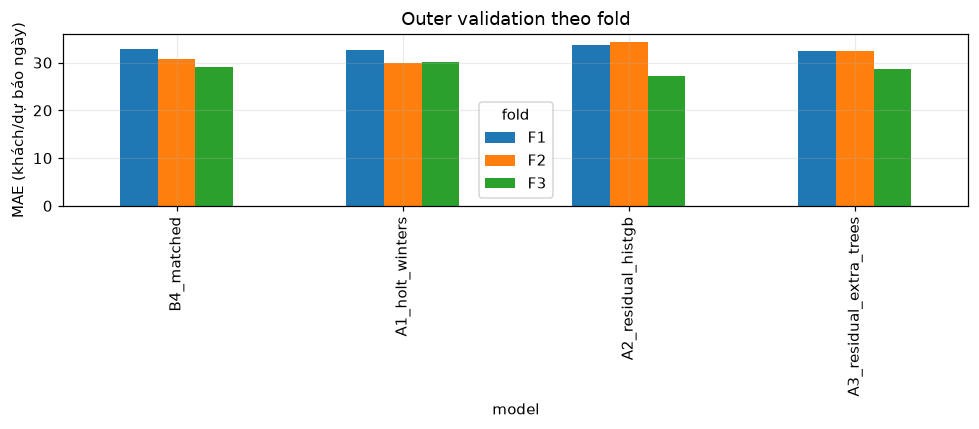

In [45]:
fig, ax = plt.subplots(figsize=(9, 4))
ranking.set_index('model')[['F1', 'F2', 'F3']].plot.bar(ax=ax)
ax.set(ylabel='MAE (khách/dự báo ngày)', title='Outer validation theo fold')
fig.tight_layout()
fig.savefig(OUT / 'validation.png')
plt.show()

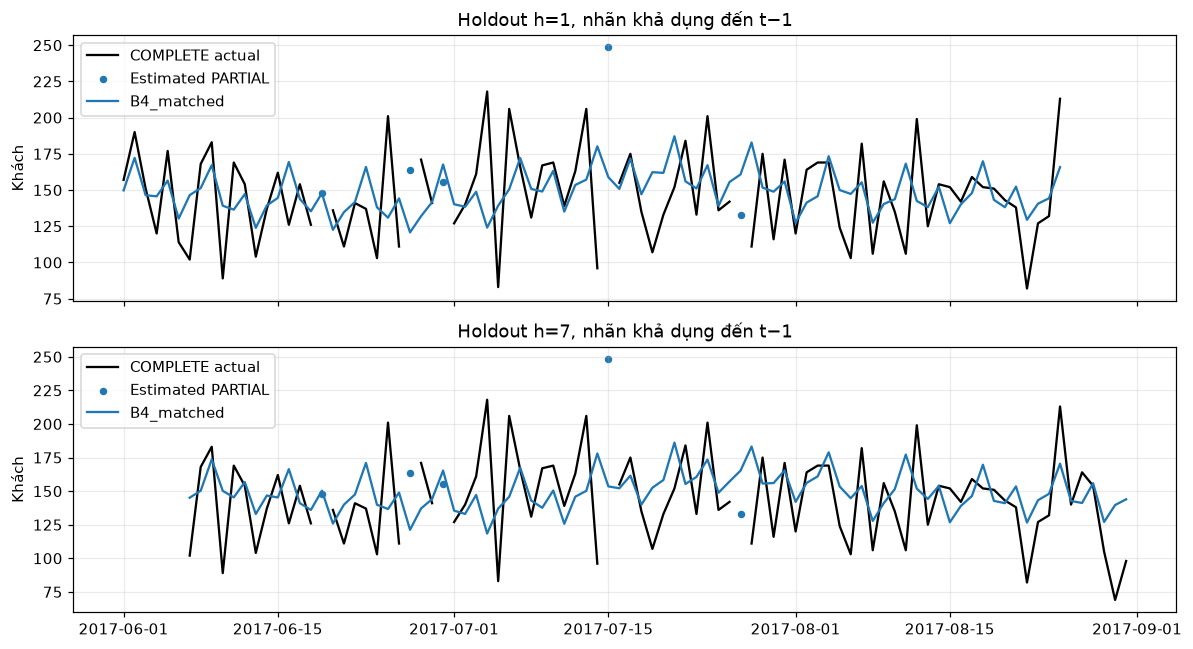

Chọn **B4_matched** từ validation, test MAE **24.96** khách. Có phương pháp mới đạt MAE 15–20: **False**.

In [46]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for ax, h in zip(axes, (1, 7)):
    selected = holdout[holdout.model.eq(SELECTED) & holdout.horizon.eq(h)]
    ax.plot(selected.target_date, selected.target_true, color='black', label='COMPLETE actual')
    missing = selected[selected.target_is_imputed]
    ax.scatter(missing.target_date, missing.target_estimated, s=15, label='Estimated PARTIAL')
    for name in dict.fromkeys(('B4_matched', SELECTED)):
        p = holdout[holdout.model.eq(name) & holdout.horizon.eq(h)]
        ax.plot(p.target_date, p.y_pred, label=name)
    ax.set(title=f'Holdout h={h}, nhãn khả dụng đến t−1', ylabel='Khách')
    ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'holdout.png')
plt.show()
row = comparison[comparison.selected].iloc[0]
Markdown(f"Chọn **{SELECTED}** từ validation, test MAE **{row.holdout_MAE:.2f}** khách. "
                 f"Có phương pháp mới đạt MAE 15–20: **{bool(comparison[comparison.model.isin(METHODS)].holdout_MAE.between(15, 20).any())}**.")

## Lưu kết quả và kiểm tra khả năng chạy lại

Lưu bảng và manifest theo run riêng. Đối chiếu checksum nguồn và notebook cũ
sau thực nghiệm, các kết quả số ở trên được tính lại trong lần Run All này.

In [47]:
checks = {
    'inputs_unchanged': all(sha(SOURCE_DIR / name) == value for name, value in source_hashes.items()),
    'old_notebooks_unchanged': all(sha(ROOT / name) == value for name, value in old_hashes.items()),
    'selection_unchanged': sha(OUT / 'selection.json') == selection_hash,
    'future_feature_check': bool(future_safe),
    'room_source_unchanged': sha(room_path) == room_source['sha256'],
}
assert all(checks.values()), checks
save_json('verification.json', {'checks': checks, 'passed': True, 'fresh_execution': True,
                                'source_point_in_time_verified': False})
notebook = json.loads(NOTEBOOK_PATH.read_text(encoding='utf-8'))
code_hash = hashlib.sha256(json.dumps([c['source'] for c in notebook['cells']
                          if c['cell_type'] == 'code'], ensure_ascii=False).encode()).hexdigest()
save_json('artifact_manifest.json', {'files': {p.name: sha(p) for p in OUT.iterdir() if p.is_file()},
                                      'notebook_code_sha256': code_hash})
pd.Series(checks, name='passed')

inputs_unchanged           True
old_notebooks_unchanged    True
selection_unchanged        True
future_feature_check       True
room_source_unchanged      True
Name: passed, dtype: bool

In [48]:
print('Hoàn tất:', OUT.relative_to(ROOT))

Hoàn tất: artifacts\forecasting\history_demand_causal_methods_report\20261110T051148_90f6fbc3
